# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Fernando Arreola Treviño
#### **Matrícula:** A01840331

## Objetivo
Notebook de **exploración** del proyecto MiBici: carga y descripción del dataset de viajes ya consolidado en Parquet, análisis exploratorio de datos (EDA) y evidencia para las decisiones de limpieza que acordará el equipo.

La pregunta que me corresponde es la **P2 (clasificación)**: ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles en un periodo futuro?

La lógica que se reutilice se trasladará al módulo del proyecto; en este notebook se desarrolla y se documenta la evidencia que la justifica.

## Dataset
**Datos abiertos de MiBici**, el sistema de bicicleta pública del Área Metropolitana de Guadalajara. El portal publica:
- **Viajes por mes** (`datos_abiertos_AAAA_MM.csv`) desde diciembre de 2014. Cada registro es un viaje con identificador, datos del usuario, fecha y hora de inicio y fin, y estaciones de origen y destino.
- **Nomenclatura de estaciones** (`nomenclatura_AAAA_MM.csv`) con identificador, nombre, latitud, longitud y capacidad de cada estación.

- Fuente: [Datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/)
- Rango analizado: **enero de 2020 a septiembre de 2026**, acordado por el equipo para homologar el EDA. Puede recortarse después con base en los hallazgos.

Se cuenta con lógica implementada para descargar los archivos en un rango especificado y en formato parquet, homologando la codificación y estandarización de fechas (`dataset.py`). Se usó este código para descargar los datos del 2020 al 2026 en la carpeta data/raw.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import sys
import os
import glob
import pyarrow
from datetime import date
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import re

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.11.5
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
matplotlib  : 3.11.2


## Configuración global


In [2]:
# Rutas del proyecto (el notebook se ejecuta desde notebooks/)
RUTA_PROYECTO = Path.cwd().parent
DATA_DIR = RUTA_PROYECTO / "data" / "processed"
ESTACIONES_DIR = RUTA_PROYECTO / "data" / "raw" / "estaciones"

# Horas sin servicio de MiBici
SIN_SERVICIO = [1, 2, 3, 4]

SEMILLA = 42

## Carga y descripción de datos

Se define una función para leer los datos (obtenidos corriendo el archivo dataset.py de este proyecto):

In [45]:
def leer_datos():
    parquet_file = glob.glob(os.path.join(DATA_DIR, "viajes_limpios*.parquet"))[0]
    return pd.read_parquet(parquet_file)

El rango escogido a analizar es de enero del 2020 a septiembre del 2026.

In [4]:
df = leer_datos()

Se describe el dataframe: nombres de columnas, tipo de datos, conteo de valores no nulos.

In [5]:
df.info(show_counts=True, memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 27026645 entries, 0 to 27026644
Data columns (total 9 columns):
 #   Column              Non-Null Count     Dtype         
---  ------              --------------     -----         
 0   viaje_id            27026645 non-null  Int64         
 1   usuario_id          27026645 non-null  Int64         
 2   genero              26889348 non-null  category      
 3   anio_de_nacimiento  26988746 non-null  Int16         
 4   inicio_del_viaje    27026645 non-null  datetime64[us]
 5   fin_del_viaje       27026645 non-null  datetime64[us]
 6   origen_id           27026645 non-null  Int32         
 7   destino_id          27026645 non-null  Int32         
 8   periodo_archivo     27026645 non-null  category      
dtypes: Int16(1), Int32(2), Int64(2), category(2), datetime64[us](2)
memory usage: 1.2 GB


## Exploración de los datos

El resultado de dataset.py ya omite duplicados.

Se visualiza el número de viajes por mes:

In [ ]:
def redondear_a_primer_dia_del_mes(dt_col):
    """Redondear fechas en formato ISO8601 al primer día del mes más cercano"""
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

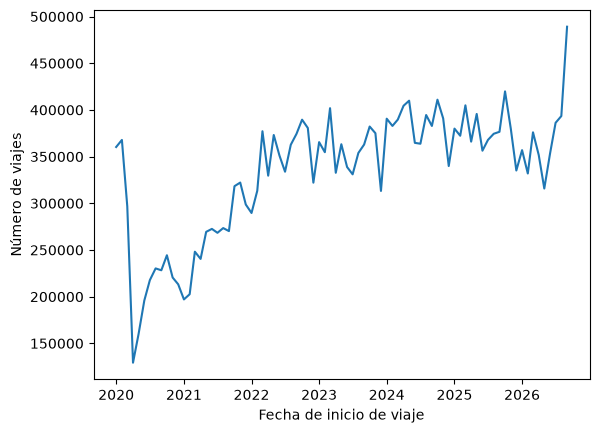

In [7]:
groupedby = df.groupby(redondear_a_primer_dia_del_mes(df["inicio_del_viaje"]))['viaje_id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

Se calcula el número de valores nulos:

In [ ]:
# Solo Genero y Año de nacimiento tienen nulls
df.isna().sum()

Se analiza si existe correlación entre Género y Año de Nacimiento en cuanto a su distribución. La correlación obtenida es baja, y por lo tanto no existe correlación entre la distribución de nulos de ambas columnas.

In [ ]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["genero","anio_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

In [ ]:
null_matrix.sum(axis=1).value_counts()

Se analiza el dataframe por tipo de dato:

In [11]:
cat_cols = df.select_dtypes(include=["str","object", "category"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

Primero se analizan las categóricas:

In [ ]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2026_09 es el que tiene más records

Se obtiene la distribución porcentual de género:

In [ ]:
df["genero"].value_counts()*100/len(df)

Ahora se analizan las numéricas:

In [ ]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df



Existen años de nacimiento inusualmente antiguos. Se asume que pudo ser un error de usuario al registrarse en la aplicación. Dado que este problema (P2) no requiere un análisis de los usuarios, eliminar estos registros potencialmente implica eliminar viajes válidos. Por lo tanto, se conservan.

Ahora se analizan los IDs. Primero los de viaje:

In [15]:
(df["viaje_id"].value_counts() > 1).sum()

0

No existen IDs de viaje duplicados.

Ahora se limpian los IDs de origen y destino. Estos requieren analizar también los IDs de estaciones del archivo de nomenclaturas, y por lo tanto se carga primero:

In [16]:
def leer_estaciones():
    csv_file = glob.glob(os.path.join(ESTACIONES_DIR, "*.csv"))[0]
    return pd.read_csv(csv_file)

In [17]:
estaciones_df = leer_estaciones()

In [18]:
estaciones_df.head(10)

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11
5,8,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11
6,9,(GDL-007) C. Epigmenio Glez./Av. Cristobal C.,20.666771,-103.350562,15
7,10,(GDL-008) C. Ignacio Zaragoza / C. J. Angulo,20.681953,-103.349992,15
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23
9,12,(GDL-010) C. Cruz verde / C. Joaquin Angulo,20.681852,-103.357338,15


El problema a analizar requiere analizar la capacidad de cada estación. Por lo tanto, primero se descartan estaciones con capacidad de 0:

In [19]:
estaciones_df = estaciones_df[estaciones_df["dpcapacity"] > 0]

Ahora, en el dataframe de viajes, se descartan records con orígenes y destinos no presentes en el dataframe de estaciones:

In [20]:
# Si un id no está en el archivo de la nomenclatura, no es posible analizarlo para el problema P2. Los records con estos ids se eliminan
def descartar_records_con_id_inexistente_en_nomenclatura(datos_df, estaciones_df, col_origen, col_destino, col_id_nomenclatura):
    datos_df = datos_df.copy()
    origen_id_no_en_nomenclatura = ~(datos_df[col_origen].isin(estaciones_df[col_id_nomenclatura].unique()))
    destino_id_no_en_nomenclatura = ~(datos_df[col_destino].isin(estaciones_df[col_id_nomenclatura].unique()))
    return datos_df[~(origen_id_no_en_nomenclatura | destino_id_no_en_nomenclatura)]

In [21]:
df = descartar_records_con_id_inexistente_en_nomenclatura(df, estaciones_df, "origen_id", "destino_id", "id")

Finalmente, se analizan las columnas de tiempo.

In [22]:
df[time_cols].describe().T

,count,mean,min,25%,50%,75%,max
inicio_del_viaje,27026645,2023-08-28 13:58:31.854078,2020-01-01 06:02:20,2022-03-09 18:20:17,2023-10-06 07:50:05,2025-03-29 13:00:38,2026-09-30 23:59:48
fin_del_viaje,27026645,2023-08-28 14:09:32.073245,2020-01-01 06:05:38,2022-03-09 18:31:52,2023-10-06 08:00:59,2025-03-29 13:11:29,2026-10-01 00:14:52


Ambas variables tienen rangos esperados: primer viaje inició el 1 de enero del 2020, el último viaje inició el 30 de septiembre del 2026. Cabe destacar que algunos de los viajes que iniciaron el 30 de septiembre, concluyeron en las primeras horas del 1 de octubre del 2026. No se desea evaluar la capacidad de las estaciones más allá de septiembre 2026; por lo tanto, se filtran estos records:

In [23]:
# 16 records terminaron después de septiembre 2026
sum(df["fin_del_viaje"] >= '2026-10-01 00:00:00')

16

In [24]:
df = df[df["fin_del_viaje"] < '2026-10-01 00:00:00']

Ahora se evalua si existen registros con duraciones de tiempo no realistas.

In [25]:
df["duracion_del_viaje"] = (df.fin_del_viaje - df.inicio_del_viaje).dt.total_seconds()

In [26]:
df["duracion_del_viaje"].describe() / (60*60*24)

count    312.808206
mean       0.007641
std        0.006592
min        0.000012
25%        0.003981
50%        0.006574
75%        0.010255
max        0.999444
Name: duracion_del_viaje, dtype: float64

Todos los viajes duran menos de 24 horas. Los datos obtenidos de dataset.py deben filtrar records que no cumplen con estas condiciones; por lo tanto, este resultado se considera apropiado. Adicionalmente, no existen registros que inicien y terminen al mismo tiempo.

Implícito a estos resultados es que ningún viaje termina antes de iniciar, lo cual corresponde con lo esperado de las definiciones de las columnas de inicio y fin de viaje. Esto se puede validar:

In [27]:
df[df["inicio_del_viaje"] >= df["fin_del_viaje"]]

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,periodo_archivo,duracion_del_viaje


No se necesita la duración del viaje y por lo tanto se elimina.

In [28]:
df = df.drop("duracion_del_viaje", axis=1)

Finalmente, la página de MiBici indica que el servicio está habilitado de 5 AM a 12:59 AM. Por lo tanto, se filtran records cuyo inicio de viaje esté fuera de este rango; para este análisis, se consideran anómalos.

In [29]:
df = df[~df["inicio_del_viaje"].dt.hour.isin([1,2,3,4])]

## Exploración a nivel de espacio de eventos

Para el problema P2, el dataframe de viajes es inapropiado. Para estimar el cambio en capacidad a lo largo del tiempo (y después categorizar si una estación está en riesgo de quedarse sin inventario o sin anclajes), es necesario que cada registro sea un evento (salida o entrada de una bici en una estación). Se define una función para hacer esta conversión.

In [ ]:
def obtener_dataframe_de_eventos(viajes, estaciones):
    """Convertir dataframe de viajes a dataframe de eventos.
    En el dataframe de eventos, cada registro es un cambio en número de bicicletas para una estación.
    Si sale una bicicleta, delta=-1, si entra una bicicleta, delta=1
    La columna orden se usa para romper empates al momento de calcular la suma acumulada (salida primero, entrada después)
    """
    salidas = pd.DataFrame({"tiempo": viajes["inicio_del_viaje"], "estacion": viajes["origen_id"], "delta": -1, "orden": 0})
    entradas = pd.DataFrame({"tiempo": viajes["fin_del_viaje"], "estacion": viajes["destino_id"], "delta": 1, "orden": 1})
    eventos = pd.concat([salidas, entradas], ignore_index=True)
    eventos = eventos.sort_values(["estacion", "tiempo", "orden"], kind="stable").reset_index(drop=True)
    eventos_con_capacidad = pd.merge(eventos, estaciones[["id","dpcapacity","latitude","longitude"]], how="left", left_on="estacion", right_on="id")
    eventos_con_capacidad = eventos_con_capacidad.drop("id", axis=1)
    eventos_con_capacidad["cumsum"] = eventos_con_capacidad.groupby("estacion")["delta"].cumsum()
    
    return eventos_con_capacidad

eventos_df = obtener_dataframe_de_eventos(df, estaciones_df)

In [31]:
eventos_df.head(10)

,tiempo,estacion,delta,orden,dpcapacity,latitude,longitude,cumsum
0,2020-01-01 08:05:09,2,-1,0,15,20.666378,-103.34882,-1
1,2020-01-01 08:05:19,2,1,1,15,20.666378,-103.34882,0
2,2020-01-01 08:05:30,2,-1,0,15,20.666378,-103.34882,-1
3,2020-01-01 10:01:28,2,1,1,15,20.666378,-103.34882,0
4,2020-01-01 11:15:49,2,1,1,15,20.666378,-103.34882,1
5,2020-01-01 11:18:26,2,-1,0,15,20.666378,-103.34882,0
6,2020-01-01 11:47:41,2,1,1,15,20.666378,-103.34882,1
7,2020-01-01 11:51:18,2,1,1,15,20.666378,-103.34882,2
8,2020-01-01 14:40:22,2,1,1,15,20.666378,-103.34882,3
9,2020-01-01 14:40:29,2,1,1,15,20.666378,-103.34882,4


In [32]:
eventos_df.size

432422976

La función anterior incluye una suma acumulada por estación a lo largo del tiempo. Esta muestra los cambios de entradas y salidas de bicicletas a lo largo del tiempo.

Se seleccionan aleatoriamente 6 estaciones para observar los cambios de entradas y salidas de bicicletas con el tiempo (con semilla fija por reproducibilidad). Inmediatamente se destaca un problema:

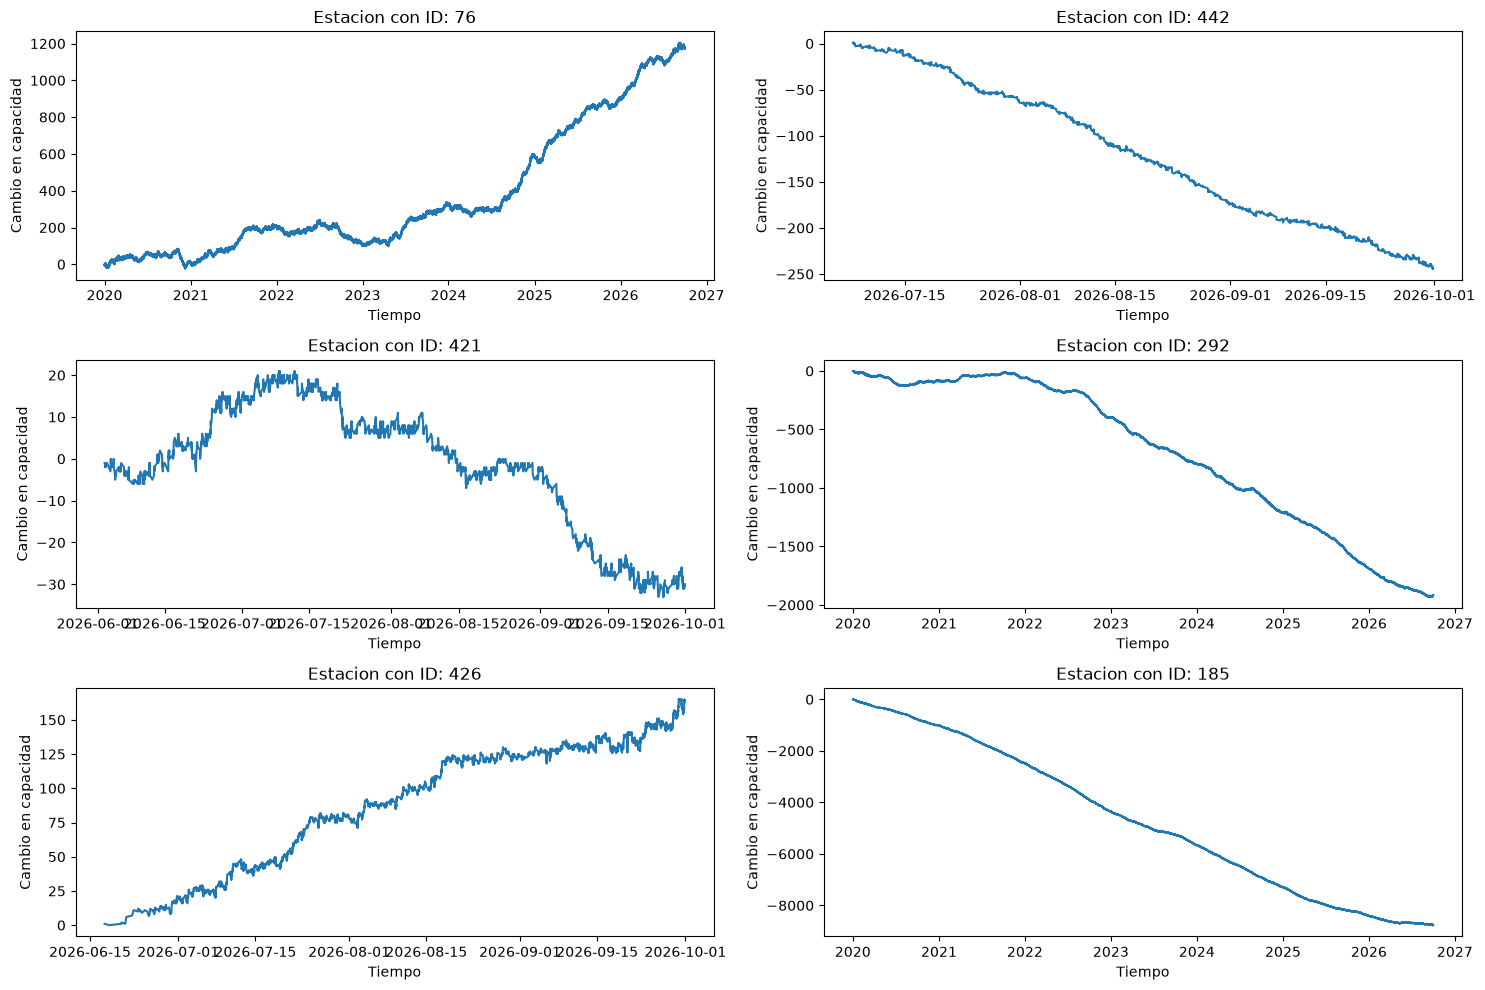

In [33]:
estaciones = estaciones_df["id"].sample(n=6, random_state=SEMILLA)
plt.figure(figsize=(15,10))
for i, estacion in enumerate(estaciones):
    plt.subplot(3,2,i+1)
    eventos_de_estacion = eventos_df[eventos_df["estacion"] == estacion]
    plt.plot(eventos_de_estacion["tiempo"], eventos_de_estacion["cumsum"])
    plt.xlabel("Tiempo")
    plt.ylabel("Cambio en capacidad")
    plt.title(f"Estacion con ID: {estacion}")

plt.tight_layout()
plt.show()

Las estaciones con datos desde el 2020 muestran tendencias que no se mantienen dentro de la capacidad de la estación. Se hace un análisis más exhaustivo a continuación, calculando el rango de la suma acumulada de movimientos y comparándola con la capacidad de cada estación.

In [34]:
rango = eventos_df.groupby("estacion")["cumsum"].agg(lambda s: s.max() - s.min())
cap = estaciones_df.set_index("id")["dpcapacity"].reindex(rango.index)
print("rango (max-min) del cumsum, mediana:", rango.median(), "| capacidad mediana:", cap.median())
print("% de estaciones cuyo cumsum recorre MÁS que su capacidad:", round(100 * (rango > cap).mean(), 1))

rango (max-min) del cumsum, mediana: 4156.0 | capacidad mediana: 15.0
% de estaciones cuyo cumsum recorre MÁS que su capacidad: 99.2


Se dan conclusiones de este análisis a continuación:

El dataset no provee datos apropiados para realizar un análisis de cambios en inventario para una estación a lo largo del tiempo. Esto se debe a tres razones:
1. No está definido un punto de partida de inventario por estación. Si se comienza el análisis desde el 1 de enero del 2020 y en ese mismo día una estación tiene su primer viaje, pierde una bicicleta en ese momento, pero no hay manera de saber cuántas bicicletas tenía al momento que inició este primer viaje cubierto por el análisis. El análisis anterior asumió que todas las estaciones inician en inventario 0, lo cual no es realista.
2. Es de esperarse que cada estación tenga reabastecimientos, particularmente al analizar periodos largos de tiempo. Las bicicletas en circulación en el 2020 no necesariamente serán las mismas que en el 2026: algunas se retiran de circulación, y algunas se agregan. Los datos no dan una manera de integrar los reabastecimientos al análisis.
3. Incluso si se estimara un valor de inventario inicial para cada estación, con un valor de entre 0 y su capacidad máxima, el análisis hecho anteriormente revela un hecho importante: algunas estaciones son más populares como origen que como destino, y viceversa. Como ejemplo visual: las gráficas anteriores muestran incrementos o decrementos relativamente constantes para sus estaciones. Las que tienden a incrementar son las que son más populares como destinos (reciben más bicicletas de las que salen), y las que tienden a decrementar son más populares como puntos de partida (salen más bicicletas de las que reciben). Como no se cuenta con datos de reabastecimiento, este punto dificulta todavía más el análisis.

El problema, por lo tanto, se ajustará de la siguiente manera: Se clasificará una estación como en riesgo si, en un futuro cercano, presenta un cambio proporcionalmente alto respecto a su inventario total. El riesgo será de quedarse sin bicicletas si el cambio es negativo, y si el cambio es positivo el riesgo será de quedarse sin anclajes disponibles.

Se desarrollará este dataframe en la libreta 0.03-fat-feature-engineering-p2, debido a que esto ya clasifica como desarrollo de características.

In [48]:
# Se guardan los resultados limpios del dataframe de viajes:
df.to_parquet(os.path.join(DATA_DIR, "p2_datos_viajes.parquet"))